# 05 · QA checks and metrics

*Turning measurements into verdicts and finding out how often the verdicts are right.*

Notebook 04 broke 27 stations on purpose and wrote down exactly what it broke. Now we try to catch it. This notebook builds a set of checks that each look at the data from one angle, combines what they say into a verdict on every station-hour (**pass**, **suspect** or **quarantine**) and then scores those verdicts against the answer key.

Then comes the part that matters most. We point the same checks at the real data where nobody planted anything. They find the two broken sensors from notebook 03 straight away, then two more that NOAA passed, and a lot of false alarms that turn out to be weather. Reading those false alarms one by one teaches more about QA than any of the scores.

By the end we'll have a verdict on every station-hour, recall against fault size for every check, precision on planted and on real data, a month-by-month monitoring history and three real stations explained.

## What "quality" means here

Before writing checks it helps to say what we're measuring. Three kinds of metric cover it and the monitoring at the end records all three every month.

**Coverage** asks whether the data is there. The simplest version is completeness, the share of expected station-hours that have a value. Notebook 04 showed why that isn't enough on its own. A station can be 95% complete and still have lost almost every storm, so coverage also has to be measured per weather condition.

**Correctness** asks whether the values that are there are right. No single number gives it directly, which is why we need checks and verdicts. It's measured as the share of hours that pass and, on planted data, as the checks' recall and precision.

**Consistency** asks whether a source agrees with independent sources and with its own past. For stations that's the difference from HRRR and from the neighbours, and whether that difference stays steady month to month. Notebook 03 showed a healthy station's monthly mean difference moves by only a few tenths of a degree.

## The checks

Each check writes one flag per station-hour. They run from cheap to subtle and they're grouped by where their evidence comes from, because that decides how much to trust two of them agreeing.

**From the station itself**
- **physical**: the value is possible. California's records are about −45 °C and 56.7 °C, and dew point can't be above the air temperature.
- **climatology**: the value is plausible for this station, month and hour of day, judged against the station's own 2015–2020 history. That history is older than the data being checked so it can't be contaminated by the faults.

**From HRRR**
- **reference**: this hour's difference from HRRR compared with the station's normal difference *for that hour of day*. Notebook 03 showed the difference has a daily cycle, so a single normal would be blurrier.
- **timing**: a whole day whose difference swings far more through the day than usual. That's what a time offset looks like, since it leaves the average untouched (notebook 04).
- **stuck**: the same value repeated for at least 6 hours while HRRR says the temperature moved by 5 °C or more. A flat run alone is normal on quiet nights.
- **shift**: a lasting change in the daily station-minus-HRRR difference, found by comparing the 30 and 90 days after each day with the 30 and 90 days before it.

**From the neighbours**
- **neighbour**: the station's difference from HRRR compared with the median difference of its five nearest stations within 100 km at the same hour. When HRRR gets a whole region wrong the neighbours share the error and it cancels. Duplicate stations are never each other's neighbours.
- **changepoint**: the same before-and-after test as shift, run on the neighbour-adjusted difference.

**Per station-month**
- **coverage**: a station that's much less complete in storm hours than in calm hours. Storm hours come from the neighbours' wind and rain, since a station that loses a storm loses its own wind and rain readings too.

All the thresholds use **robust** statistics. Instead of the mean and standard deviation they use the median and the median absolute deviation (MAD), so a fault that's in the data doesn't stretch the yardstick used to find it. Every threshold also has a floor in °C so a very steady station doesn't get flagged for tiny wobbles. The values are in `wxlab.qa.THRESHOLDS` and were tuned on the untouched stations to keep false alarms rare.

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from wxlab import stations as st, reference as ref, faults as fl, qa

plt.rcParams["figure.dpi"] = 80
REF_DIR = Path(DATA_DIR) / "reference"
QA_DIR = Path(DATA_DIR) / "qa"

# The real matched table (notebook 03) and the planted data for seed 0 (notebook 04).
reference = ref.load(REF_DIR / "hrrr")
model_elev = pd.read_parquet(REF_DIR / "hrrr_model_elevation.parquet").set_index("station_id").model_elevation_m
hourly = st.load_standardized(Path(DATA_DIR) / "standardized" / "isd", years=range(2021, 2025))
matched = ref.match(hourly, reference, model_elev).dropna(subset=["hrrr_air_temperature"])
planted, catalogue, stats, holdout = fl.load(DATA_DIR, seed=0)
history = st.load_station_history(Path(DATA_DIR) / "meta").set_index("station_id")

# Climatology from each station's own 2015–2020 record, and neighbours without duplicates.
older = st.load_standardized(Path(DATA_DIR) / "standardized" / "isd", station_ids=matched.station_id.unique(), years=range(2015, 2021))
clim = qa.climatology(older)
points = pd.read_parquet(REF_DIR / "station_points.parquet")
dups = fl.duplicate_pairs(matched)
nbrs = qa.neighbours(points[points.station_id.isin(planted.station_id.unique())], dups)
print(f"climatology from {len(older):,} older station-hours; "
      f"{sum(len(v) >= 2 for v in nbrs.values())} of {len(nbrs)} baseline stations have at least two neighbours")

climatology from 7,799,335 older station-hours; 96 of 107 baseline stations have at least two neighbours


## Step 1 · Running the checks once

Here's every check on the planted data for seed 0. It takes a few seconds for 3.7 million station-hours. The first thing to look at is how often each check fires on the stations we *didn't* touch, because every one of those flags is a false alarm or a real fault that slipped into the baseline.

In [3]:
flags, coverage, _ = qa.run_checks(planted, clim, nbrs)
untouched = ~flags.station_id.isin(catalogue.station_id)
rates = pd.DataFrame({"untouched stations": flags.loc[untouched, qa.HOURLY_CHECKS].mean(),
                      "faulty stations": flags.loc[~untouched, qa.HOURLY_CHECKS].mean()}) * 100
print("share of hours flagged (%)"); print(rates.round(3).to_string())
print("\nverdicts on untouched stations:", flags.loc[untouched, "verdict"].value_counts(normalize=True).round(4).to_dict())

share of hours flagged (%)
             untouched stations  faulty stations
physical                  0.000            0.670
climatology               0.034            0.061
reference                 0.053            0.439
timing                    0.235            1.507
stuck                     0.001            0.040
shift                     0.974            3.386
neighbour                 0.049            0.357
changepoint               0.771            3.283

verdicts on untouched stations: {'pass': 0.9777, 'suspect': 0.0147, 'missing': 0.0073, 'quarantine': 0.0003}


On untouched stations the hour-level checks each fire on about 0.05% of hours or less. The day-level ones (timing, shift and changepoint) fire more often because one alarm marks a whole day. Faulty stations light up much more, as they should.

## Step 2 · From flags to verdicts

A flag is one check's opinion. A **verdict** combines them:

- **pass**: no check fired.
- **suspect**: at least one check fired.
- **quarantine**: checks from two different evidence groups agree *and* at least one of them judged that specific hour.

Steps and drifts get their own output. They never look wrong hour by hour, so they'd rarely reach quarantine. When both shift detectors (one against HRRR and one against the neighbours) see a lasting shift on the same days, those days get a **break** flag. A break says the station's record changed character around then. Climate datasets call this an inhomogeneity and treat it as a property of a period. What to do about it (drop a segment, adjust it or keep both) is a different decision from judging single hours, and notebook 09 makes it for the model.

Values are never deleted. The verdict sits next to the value along with every flag, so a user can choose their own strictness.

The rules took three tries and both wrong versions are worth knowing.
- **Any two groups could quarantine an hour.** That quarantined whole days at Montgomery Field in San Diego during the stormy February of 2024, where the values were within about a degree of HRRR. Two *day-level* checks (timing and changepoint) had agreed and every hour of those days got condemned. A pattern across a day can support a verdict on an hour but shouldn't decide it alone.
- **Two agreeing shift detectors could quarantine on their own.** On the real data that quarantined months of good data *before* each step too, because a before-and-after test lights up on both sides of a change. That's when breaks became their own output.

## Step 3 · Recall against fault size

One seed gives one or two faults per type and size, so the scores below come from 20 seeds. Each seed plants different faults at different stations and dates and the checks run from scratch. That takes a few minutes the first time and gets cached under `data/qa/seeds/`.

For each fault a check *detects* it if it flags at least 3 hours at that station inside the fault's scoring window. The window is about the fault and not the whole station:

- **step and bias**: within 30 days of the onset.
- **drift and time offset**: from the onset to 30 days after the end.
- **stuck**: from a day before to a day after.
- **storm gaps**: any month of the fault, by the coverage check only.

There's also a **chance** line. It scores the exact same windows on random untouched stations. That shows how often a check would "detect" a fault that isn't there just from background false alarms, which matters most for long windows.

20 seeds, 540 planted faults scored


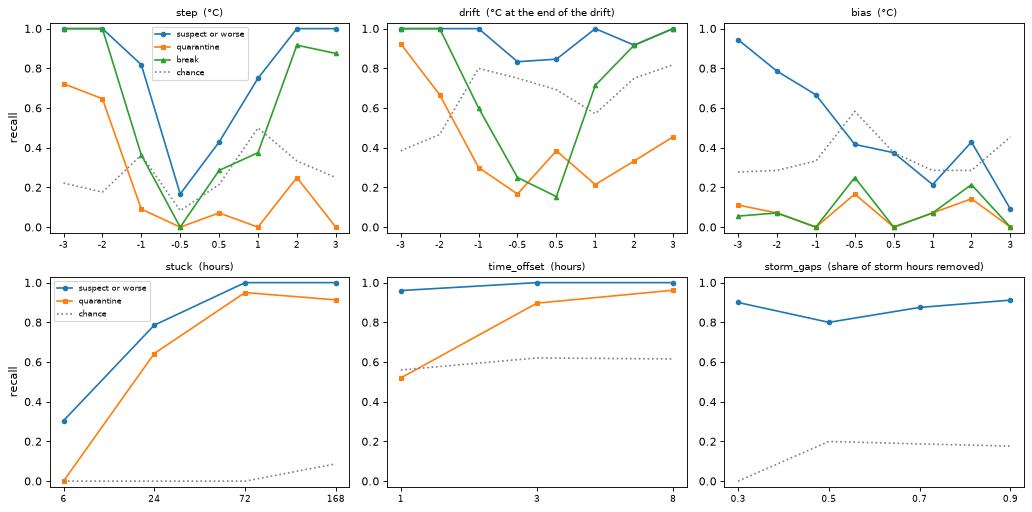

In [4]:
scores, chance, prec = qa.evaluate_seeds(matched, clim, points, dups, seeds=range(20), cache_dir=QA_DIR / "seeds")
print(f"{scores.seed.nunique()} seeds, {len(scores)} planted faults scored")

types = ["step", "drift", "bias", "stuck", "time_offset", "storm_gaps"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, t in zip(axes.ravel(), types):
    s, c = scores[scores.fault_type == t], chance[chance.fault_type == t]
    main = "coverage" if t == "storm_gaps" else "suspect"
    lines = [(main, "-o", "suspect or worse" if main == "suspect" else "coverage check"), ("quarantine", "-s", "quarantine")]
    if t in ("step", "drift", "bias"):
        lines.append(("break", "-^", "break"))
    for col, style, label in lines:
        if t == "storm_gaps" and col == "quarantine":
            continue
        r = s.groupby("fault_size")[col].mean()
        ax.plot(range(len(r)), r.values, style, label=label, ms=4)
    ch = c.groupby("fault_size")[main].mean()
    ax.plot(range(len(ch)), ch.values, ":", color="gray", label="chance")
    ax.set_xticks(range(len(ch))); ax.set_xticklabels([f"{x:g}" for x in ch.index], fontsize=8)
    ax.set_ylim(-0.03, 1.03); ax.set_title(f"{t}  ({fl.SIZES[t][1]})", fontsize=9)
axes[0, 0].legend(fontsize=7); axes[1, 0].legend(fontsize=7); axes[0, 0].set_ylabel("recall"); axes[1, 0].set_ylabel("recall")
plt.tight_layout(); plt.show()

Each panel reads left to right from big cold faults to big warm ones (or short to long). A few things stand out.

**Steps** of 1 °C and up get at least a suspect verdict most of the time. The break line shows how often both shift detectors agree, which is the stricter answer and the one to trust before dropping or adjusting data. Breaks catch nearly every step of 2 °C or more and only about a third at 1 °C. A 0.5 °C step sits inside the normal wander of a station's difference from HRRR and is barely above chance. That matches the literature on homogenizing climate records, where breaks smaller than about half a degree are hard to find without metadata. Cold faults do a bit better than warm ones because they can push the temperature below the dew point and trip the physical check.

**Drifts** look well caught at the suspect level, but the chance line is high too because a drift's window is long. The honest signal is the break line, which catches drifts that reach 2 °C or more and few smaller ones.

**Bias** stays close to the chance line for warm biases, as notebook 04 predicted. A bias that starts on the first day of the data has no "before" to compare with. The real catch is cold biases. At 2–3 °C cold they push the temperature below the dew point at humid stations and the physical check fires right away.

**Stuck sensors** are caught from about a day upward and mostly missed at 6 hours, where they look like a quiet night. **Time offsets** of 3 and 8 hours are quarantined almost every time and a 1-hour offset about half the time. **Storm gaps** are caught by the coverage check 80–90% of the time at every size, far above chance.

The chance line is near zero for stuck sensors, whose window is a few days, and high for drifts and time offsets, whose windows run for months. For long windows a share of the "detections" would have happened anyway, so the honest number is the gap between the solid line and the dotted one.

## Step 4 · Precision

Precision asks the opposite question: of the station-months where a check raised an alarm, how many were really inside a planted fault?

In [5]:
p = prec.groupby(level=0).agg(precision=("precision", "mean"), sd=("precision", "std"), alarms_per_seed=("alarms", "mean"))
p.loc[qa.HOURLY_CHECKS + ["break", "suspect", "quarantine", "coverage"]].round(2)

,precision,sd,alarms_per_seed
physical,1.00,0.00,75.15
climatology,0.17,0.04,155.45
reference,0.18,0.04,185.40
timing,0.19,0.04,235.35
stuck,0.60,0.14,13.25
shift,0.31,0.03,193.50
neighbour,0.18,0.05,161.10
changepoint,0.32,0.04,173.60
break,0.36,0.04,136.35
suspect,0.25,0.03,739.10


Precision is low for most single checks. Physical is perfect because the real baseline never has dew point above temperature, so every hit is a planted cold fault. Stuck is decent. Most of the others sit around 20–35%.

Part of that is the setup. Only a quarter of stations carry a fault and each fault covers a small part of the record, so even a rare false alarm adds up across 80 healthy stations and four years. Part of it is that the "untouched" baseline isn't perfectly clean, so some false alarms are real. And part of it is weather the checks can't tell apart from a fault. The real data in step 6 shows which part is which.

## Step 5 · Monitoring month by month

In production these checks wouldn't run once over four years. They'd run on a schedule. `qa.monitor` does that. It runs the checks once per month, each run seeing only data up to the end of that month, and records metrics for every run. Early runs know less. Normals come from a few months of data, and the seasonal cycle can't be removed until two years exist. That's exactly what a new deployment looks like.

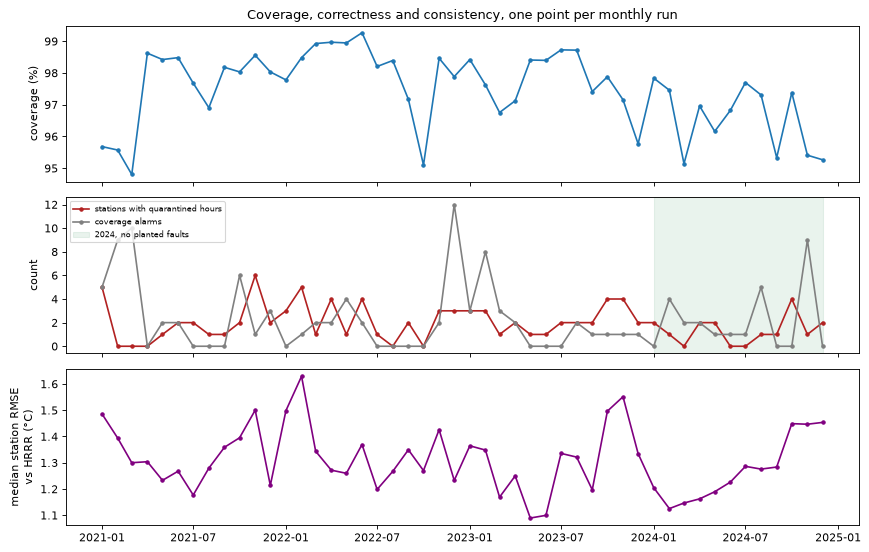

In [6]:
mon_path, monflags_path = QA_DIR / "monitoring_seed0.parquet", QA_DIR / "monitoring_flags_seed0.parquet"
if mon_path.exists():
    metrics, monflags = pd.read_parquet(mon_path), pd.read_parquet(monflags_path)
else:
    metrics, monflags = qa.monitor(planted, clim, nbrs)
    metrics.to_parquet(mon_path); monflags.to_parquet(monflags_path)

# Consistency per month: the median station's RMSE against HRRR.
month = planted.time.dt.tz_localize(None).dt.to_period("M")
rmse = planted.groupby(["station_id", month]).diff_air_temperature.apply(lambda d: np.sqrt((d ** 2).mean()))
metrics = metrics.set_index("month").join(rmse.groupby(level=1).median().rename("median_rmse"))

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
x = metrics.index.to_timestamp()
axes[0].plot(x, metrics.coverage * 100, marker="."); axes[0].set_ylabel("coverage (%)")
axes[0].set_title("Coverage, correctness and consistency, one point per monthly run")
axes[1].plot(x, metrics.stations_quarantined, marker=".", color="firebrick", label="stations with quarantined hours")
axes[1].plot(x, metrics.coverage_alarms, marker=".", color="gray", label="coverage alarms")
axes[1].axvspan(pd.Timestamp("2024-01-01"), x.max(), color="seagreen", alpha=0.1, label="2024, no planted faults")
axes[1].set_ylabel("count"); axes[1].legend(fontsize=7, loc="upper left")
axes[2].plot(x, metrics.median_rmse, marker=".", color="purple"); axes[2].set_ylabel("median station RMSE\nvs HRRR (°C)")
plt.tight_layout(); plt.show()

Coverage moves between about 95% and 99% and dips in stormy winter months. The number of stations with quarantined hours hovers between zero and six and barely changes when the planted faults stop at the end of 2023. That's the precision result again from another angle. Most monthly quarantines on this data come from weather and from whatever is wrong in the baseline rather than from planted faults, and that background is the rate an operator would learn to live with. Coverage alarms spike in the big storm months (December 2022 and November 2024) even with no planted gaps, because a station that loses power in a real storm looks exactly like a planted storm gap. Consistency follows the seasons. The median station's RMSE against HRRR is lowest in late spring and early summer and highest in winter, when inversions and fog make the near-surface temperature harder to model.

How quickly does a monthly run catch a fault after it starts?

In [7]:
c = qa.scoring_windows(catalogue)
rows = []
for x in c.itertuples():
    f = monflags[(monflags.station_id == x.station_id) & (monflags.time >= x.lo) & (monflags.time <= x.hi)
                 & ((monflags.verdict == "quarantine") | monflags["break"])]
    lag = (f.time.min() - x.first_affected).days if len(f) >= 3 else np.nan
    rows.append({"fault_type": x.fault_type, "fault_size": x.fault_size, "days_to_alarm": lag})
lags = pd.DataFrame(rows)
print("first quarantine or break after a fault starts, monthly runs, seed 0")
lags[lags.fault_type != "storm_gaps"].groupby("fault_type").days_to_alarm.agg(caught="count", total="size", median_days="median").round().astype("Int64")

first quarantine or break after a fault starts, monthly runs, seed 0


,caught,total,median_days
fault_type,,,
bias,0,5,<NA>
drift,4,5,340
step,2,5,-8
stuck,2,4,0
time_offset,3,4,2


This is seed 0, so the counts are small, but the pattern is clear. Loud faults like stuck sensors and time offsets get quarantined within a day or two of starting. Steps that get caught are caught right around the change. The median is a week *before* the onset because the before-and-after test lights up on both sides of a change, and a monthly run catches it once enough days have passed. Drifts get caught late, about eleven months in, once the error has grown large or the sensor gets replaced and the reading snaps back. Biases never get caught. That's the price of not raising an alarm on every warm afternoon.

## Step 6 · The real data

Now the same checks on the real 2021–2024 data for all stations, with nothing planted. Every alarm is either a real problem or a false alarm, and we don't know which until we look.

In [8]:
real_path = QA_DIR / "real_flags.parquet"
if real_path.exists():
    real = pd.read_parquet(real_path)
else:
    nbrs_all = qa.neighbours(points, dups)
    real, real_cov, _ = qa.run_checks(matched, clim, nbrs_all)
    real.to_parquet(real_path)
print("verdicts on real data:", real.verdict.value_counts(normalize=True).round(4).to_dict())
top = (real[real.verdict == "quarantine"].groupby("station_id").size().rename("quarantined hours")
       .sort_values(ascending=False).head(8).to_frame())
top["name"] = top.index.map(history["name"])
top

verdicts on real data: {'pass': 0.9506, 'missing': 0.0285, 'suspect': 0.02, 'quarantine': 0.0009}


,quarantined hours,name
station_id,,
72290993115,1821,NAVAL AUXILIARY LANDING FD
72583799999,319,SUSANVILLE MUNI
72291093116,271,SAN NICOLAS ISLAND NAVAL OUTLYING FIELD
69015093121,154,TWENTY NINE PALMS
72292593117,108,NALF/F. SHERMAN FLD ARPT
72292603154,102,MARINE CORPS AIR STATION
72290303131,97,MONTGOMERY FIELD AIRPORT
72026723224,94,AUBURN MUNICIPAL AIRPORT


The two broken sensors from notebook 03 come out on top by themselves, the naval airfield with about 1,800 quarantined hours and Susanville with about 300. Below them are two stations we haven't met yet, San Nicolas Island and Twenty Nine Palms. Further down the counts drop into the tens and that's where weather and real faults start to mix.

Breaks tell a similar story from the slow side.

In [9]:
brk = real[real["break"]].assign(day=lambda b: b.time.dt.floor("D"))
days = brk.groupby("station_id").day.nunique().sort_values(ascending=False)
print(f"stations with any break days: {len(days)}; with 30 or more: {(days >= 30).sum()}")
days.head(6).rename(index=history["name"]).rename("break days").to_frame()

stations with any break days: 59; with 30 or more: 29


,break days
station_id,
NAVAL AUXILIARY LANDING FD,341
SUSANVILLE MUNI,253
NORTH ISLAND NAS,186
TWENTY NINE PALMS,131
SAN NICOLAS ISLAND NAVAL OUTLYING FIELD,129
BURBANK-GLENDALE-PASA ARPT,105


The same four stations lead, which is reassuring because two independent kinds of evidence agree. Fifth is **North Island NAS**, another naval air station in San Diego Bay. It ran about 2 °C colder than San Diego's airport across the bay for November 2021 and again for February and March 2024, and the rest of the time the two track each other. Those look like real sensor episodes too. The long tail of stations with a few break days is mostly the seasonal wobble of the marine layer and fog, which is why a break needs a human look or a second kind of evidence before data gets dropped.

### Checking real alarms by hand

To estimate precision on real data we took a fixed random sample of 30 station-months with a quarantine alarm and judged each one by eye. For each one we compared the station with HRRR and with what its neighbours imply and labelled it **fault**, **weather** or **unclear**. The labels and a one-line reason for each are in [`docs/real-flag-review.csv`](../docs/real-flag-review.csv).

In [10]:
review = pd.read_csv(Path("..") / "docs" / "real-flag-review.csv")
print(review.label.value_counts().to_dict())
print(f"precision of a quarantine alarm on real data: {(review.label == 'fault').mean():.0%} clear faults, "
      f"up to {(review.label != 'weather').mean():.0%} counting the unclear ones")
review[review.label != "weather"][["name", "month", "label", "reason"]]

{'weather': 20, 'fault': 5, 'unclear': 5}
precision of a quarantine alarm on real data: 17% clear faults, up to 33% counting the unclear ones


,name,month,label,reason
0,HAYWARD EXECUTIVE AIRPORT,2023-11,fault,drops to about -18 °C for a few hours while ne...
7,JACK MCNAMARA FIELD ARPT,2024-03,fault,jumps to 31 °C for a few hours in March while ...
9,MONTEREY PENINSULA AIRPORT,2024-11,fault,drops to -12 °C on and off for a day while nei...
12,MDSTO CTY-CO H SHAM FD APT,2021-11,fault,three hours near 30 °C on a late-November even...
14,FULLERTON MUNICIPAL ARPT,2021-11,unclear,sharp single-hour drops of 5-10 °C at night; c...
18,LIVERMORE MUNICIPAL ARPT,2022-09,unclear,isolated upward spikes of 8-10 °C over a few days
20,SAN LUIS CO REGIONAL ARPT,2024-04,unclear,flat at 21 °C for several midday hours
21,PASO ROBLES MUNICIPAL ARPT,2022-01,unclear,warm spikes near 29 °C in January while neighb...
23,NAVAL AUXILIARY LANDING FD,2024-05,fault,the known 2 °F stuck value
28,SAN NICOLAS ISLAND NAVAL OUTLYING FIELD,2024-09,unclear,39 °C on an island during the September 2024 h...


Five of thirty are clear faults: sudden drops to −12 or −18 °C for a few hours at Hayward and Monterey, a spike to 31 °C in March at a coastal airport, three hours near 30 °C on a late-November evening at Modesto, and the naval airfield's stuck 2 °F. Five more are unclear, short plateaus or spikes that could go either way.

The twenty false alarms aren't random though. They fall into a few kinds of weather:

- **Heat waves at the coast.** During offshore-wind heat events (October 2024, September 2022 and 2024) coastal stations and piers run several degrees hotter than HRRR. Port San Luis alone shows up three times.
- **Wind arriving at a different hour.** Santa Ana winds and Santa Barbara's sundowner winds are very local and very fast. If HRRR brings them an hour or two early or late the station looks wrong for a few hours.
- **Fog and cold nights.** Tule fog in the Central Valley and clear calm nights make one station very different from its neighbours for reasons that are real but tiny in scale.

So real-world precision for a quarantine alarm is about 17%, but the alarms that matter most are big. Weight by hours and the picture flips, because the naval airfield alone has more quarantined hours than all the weather alarms together. The practical fix is to know the weather patterns that fool the checks and suppress or down-weight alarms during them, for example by not quarantining coastal stations during offshore-wind heat events without a third witness.

## Step 7 · Three real stations explained

The plan was to investigate the three most suspicious real stations. Two of them are notebook 03's naval airfield and Susanville, already explained as a stuck default value and a sensor pinned near the bottom of its range. The third is new.

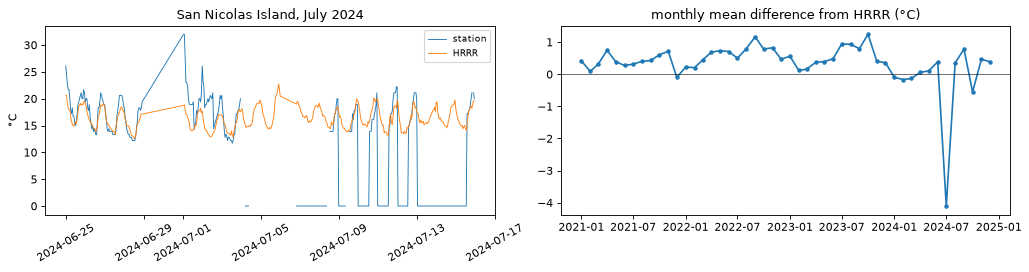

hours at exactly 0.0 °C: 203 (months ['2024-07', '2024-10']); NOAA quality codes: {'5': 153, '6': 50}


In [11]:
sni = matched[matched.station_id == "72291093116"].set_index("time")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
w = sni["2024-06-25":"2024-07-15"]
axes[0].plot(w.index, w.air_temperature, lw=0.8, label="station")
axes[0].plot(w.index, w.hrrr_air_temperature_adj, lw=0.8, label="HRRR")
axes[0].set_ylabel("°C"); axes[0].legend(fontsize=8); axes[0].set_title("San Nicolas Island, July 2024")
axes[0].tick_params(axis="x", rotation=30)
monthly = sni.diff_air_temperature.resample("MS").mean()
axes[1].plot(monthly.index, monthly.values, marker=".")
axes[1].axhline(0, color="k", lw=0.5); axes[1].set_title("monthly mean difference from HRRR (°C)")
plt.tight_layout(); plt.show()
zero = sni[sni.air_temperature == 0.0]
print(f"hours at exactly 0.0 °C: {len(zero)} (months {sorted(zero.index.strftime('%Y-%m').unique())}); "
      f"NOAA quality codes: {zero.tmp_quality.value_counts().to_dict()}")

**San Nicolas Island** is a naval outlying field on a remote island about 100 km off the Southern California coast. In July and October 2024 it reported exactly 0.0 °C for about 200 hours while HRRR had it near 18 °C. NOAA marked three quarters of those values with quality code 5 ("passed") and the rest code 6 ("suspect"). None were marked erroneous. Zero is the classic stuck default. It's what a system reports when it has no reading but still has to fill the field. The monthly difference also drops by about half a degree at the start of 2024 and stays there, which looks like a sensor change. Both shift detectors flag it.

**Twenty Nine Palms** came fourth. It's a Marine Corps base in the desert. From 13 to 30 January 2024 it ran 5–10 °C warmer than HRRR and its neighbours at every hour of the day and night, then snapped back on the 31st. NOAA passed it too.

**What the metadata says.** NOAA keeps a station history database called HOMR (Historical Observing Metadata Repository). We looked up all four stations there. It records names, locations and platforms but nothing that explains any of these faults: no sensor swap, no maintenance and no outage. Station metadata says where a station is and not how its sensor is doing, so for faults like these the data itself is the only witness. One pattern is worth noting without claiming a cause. Three of the four stations are military airfields (the naval landing field, San Nicolas Island and Twenty Nine Palms), which run their own weather equipment.

**And Moffett.** Notebook 01 found NOAA marks most of Moffett Federal Airfield's temperatures erroneous and notebook 03 found its values look fine against HRRR.

In [12]:
mof = real[real.station_id == "74509023244"]
noaa_bad = matched.loc[mof.index, "tmp_quality"].isin(["3", "7"])
print(f"Moffett: NOAA marks {noaa_bad.mean():.0%} of hours erroneous; our verdicts: "
      f"{mof.verdict.value_counts(normalize=True).round(3).to_dict()}")

Moffett: NOAA marks 91% of hours erroneous; our verdicts: {'pass': 0.999, 'suspect': 0.001}


Our checks pass almost every Moffett hour that NOAA calls erroneous. The two systems disagree flatly, and with HRRR, its neighbours and its own history all agreeing the values are fine, the NOAA flag is the likely error. A QA system that inherited NOAA's flags would have thrown away four years of good data from one station.

## What surprised me

**The real false alarms are mostly weather and they come in a few kinds.** Coastal heat waves, local winds that HRRR times slightly wrong and fog. Knowing those patterns is worth more than tuning any threshold.

**NOAA passed four broken sensors.** A sensor stuck at −39 °C, one stuck at 2 °F, one stuck at 0.0 °C and one running 10 °C warm for 18 days, all mostly marked as passed. Simple comparisons with a model and neighbours catch every one.

**Station metadata was silent on all of them.** The data was the only witness.

**Two checks built on the same evidence aren't two witnesses.** The first verdict rule quarantined whole stormy days because two day-level checks agreed. Requiring different kinds of evidence, and an hour-level one, fixed it.

**Small steps are genuinely hard.** Below about 1 °C a step hides in the normal wander of the difference from HRRR. A constant bias from day one is close to invisible.

**Monthly runs catch loud faults within a day or two and slow ones within weeks.** The delay is the price of a low false-alarm rate.

## Check yourself

<details><summary>Why does quarantine need two evidence groups rather than two checks?</summary>
Two checks on the same evidence fail together. If HRRR gets a fog bank wrong both the reference and the timing check fire, but nothing independent has confirmed the station is wrong.
</details>

<details><summary>Why is there a "chance" line on the recall plots?</summary>
For a long window even a rare false-alarm rate will eventually put a few flags inside it. The chance line scores the same windows on untouched stations, so the gap between the lines is what the check actually found.
</details>

<details><summary>A check has 90% recall on planted faults and 17% precision on real alarms. Is it good?</summary>
It depends on the cost of each mistake. For a dataset that feeds a model, quarantining a weather hour costs one training example and missing a stuck sensor teaches the model something false for weeks. Still, 17% precision means a human reviewing alarms wastes most of their time, so the next step would be to suppress the known weather patterns.
</details>

<details><summary>Why does the climatology check use 2015–2020 and not the data being checked?</summary>
So the yardstick isn't built from the faults it's trying to find. A long fault inside the checked data would pull its own climatology toward itself.
</details>

New terms from this notebook are in [`docs/glossary.md`](../docs/glossary.md).